# Student Career Success Prediction - Project Summary

## 1. Project Workflow & Steps Taken
* **Data Ingestion:** Loaded the dataset of 50,000 students (`student_career_success_dataset.csv`).
* **Data Cleaning:** Checked for duplicates and missing values (none found). Addressed extreme outlier analysis (retained all data as they represent valid, realistic variations).
* **Target Encoding:** Converted the target variable `Placement_Status` into binary format (`Placed: 1`, `Not Placed: 0`).
* **Feature Selection:** Programmatically identified and separated numerical and categorical features. Prevented data leakage by dropping highly correlated identifier and future outcome columns (`Student_ID`, `Starting_Salary_USD`, `Placement_Mode`, `Career_Field`, `Company_Tier`).
* **Data Splitting:** Executed a standard 80-20 train-test split (`40,000` training, `10,000` testing samples).
* **Preprocessing Pipeline:** Developed a highly robust `ColumnTransformer` pipeline using:
  * `SimpleImputer` and `StandardScaler` for numerical data.
  * `OrdinalEncoder` for binary categorical features.
  * `OneHotEncoder` for multiclass categorical variables.
* **Model Selection:** Built pipelines and performed stratified 5-fold cross-validation on 5 different classification algorithms.
* **Hyperparameter Optimization:** Utilized `RandomizedSearchCV` with the `SAGA` solver on the top-performing Logistic Regression model to find optimal regularizations.

---

## 2. Model Performance Summary (Cross-Validation)

| Model | Cross-Validation Accuracy | Precision | Recall | F1-Score | ROC-AUC |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Logistic Regression** | **82.11%** | **84.11%** | **95.08%** | **89.26%** | **0.8111** |
| **Random Forest** | 81.65% | 84.21% | 94.20% | 88.92% | 0.8071 |
| **XGBoost** | 81.01% | 83.95% | 93.63% | 88.52% | 0.8017 |
| **K-Nearest Neighbors (KNN)** | 79.42% | 83.59% | 91.68% | 87.45% | 0.7305 |
| **Decision Tree** | 73.56% | 83.78% | 82.08% | 82.92% | 0.6255 |

---

## 3. Best Model & Test Performance

### **Winner:** Tuned Logistic Regression
* **Parameters:** `{'classifier__penalty': 'l1', 'classifier__C': 0.0336}`
* **Best Cross-Validation Accuracy:** **82.22%**

### **Test Dataset Metrics:**
* **Accuracy:** **82.00%**
* **Precision (Class 1 - Placed):** **83.00%**
* **Recall (Class 1 - Placed):** **95.00%**
* **F1-Score (Class 1 - Placed):** **89.00%**

# import dataset

In [142]:
import pandas as pd
import numpy as np
import os

In [143]:
import kagglehub
import os
import pandas as pd

# Download latest version with the corrected dataset path
path = kagglehub.dataset_download("mobeenfatimah/student-career-success-prediction-dataset")

print("Path to dataset files:", path)

df = os.path.join(path, 'student_career_success_dataset.csv')
df = pd.read_csv(df)

Using Colab cache for faster access to the 'student-career-success-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/student-career-success-prediction-dataset


In [144]:
df.head()

,Student_ID,Age,Gender,University_Year,Major,Attendance_Percentage,Study_Hours_Per_Week,CGPA,Academic_Performance,Programming_Skill,...,Teamwork,Problem_Solving,English_Proficiency,Interview_Score,Employability_Score,Placement_Status,Company_Tier,Career_Field,Placement_Mode,Starting_Salary_USD
0,ST000001,22,Male,Sophomore,Computer Science,86,21,3.28,Good,9,...,7,8,Advanced,72,231.70,Placed,Tier 1,Backend Developer,Campus Placement,72082
1,ST000002,20,Female,Freshman,Computer Science,64,18,2.53,Poor,6,...,6,5,Basic,59,157.45,Not Placed,No Company,Not Placed,Not Applicable,0
2,ST000003,23,Male,Senior,Information Technology,75,19,2.83,Average,8,...,8,7,Advanced,76,203.45,Placed,Tier 1,IT Support Engineer,Campus Placement,94898
3,ST000004,23,Female,Senior,Information Technology,80,19,2.80,Average,5,...,6,6,Intermediate,67,171.50,Not Placed,No Company,Not Placed,Not Applicable,0
4,ST000005,23,Female,Senior,Software Engineering,73,19,2.93,Average,9,...,8,9,Advanced,82,225.45,Placed,Tier 1,Software Engineer,Internship Conversion,85256


# about the dataset

In [145]:
df.shape

(50000, 29)

In [146]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             50000 non-null  object 
 1   Age                    50000 non-null  int64  
 2   Gender                 50000 non-null  object 
 3   University_Year        50000 non-null  object 
 4   Major                  50000 non-null  object 
 5   Attendance_Percentage  50000 non-null  int64  
 6   Study_Hours_Per_Week   50000 non-null  int64  
 7   CGPA                   50000 non-null  float64
 8   Academic_Performance   50000 non-null  object 
 9   Programming_Skill      50000 non-null  int64  
 10  Projects_Completed     50000 non-null  int64  
 11  Certifications         50000 non-null  int64  
 12  Hackathons             50000 non-null  int64  
 13  GitHub_Profile         50000 non-null  object 
 14  Internships            50000 non-null  int64  
 15  Le

In [147]:
df.describe()

,Age,Attendance_Percentage,Study_Hours_Per_Week,CGPA,Programming_Skill,Projects_Completed,Certifications,Hackathons,Internships,Resume_Score,Communication_Skills,Teamwork,Problem_Solving,Interview_Score,Employability_Score,Starting_Salary_USD
count,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,21.262900,81.409640,21.52816,3.106043,7.137160,8.620560,1.715660,3.093940,4.048880,96.045740,8.435780,7.006200,7.175060,77.515400,213.991394,68988.167480
std,2.041163,9.709519,6.97481,0.290351,1.507194,2.505408,1.368301,1.660774,1.005719,7.331565,1.387543,1.606802,1.674428,12.579382,26.824224,38480.607679
min,18.000000,50.000000,5.00000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,44.000000,3.000000,2.000000,1.000000,17.000000,82.300000,0.000000
25%,20.000000,75.000000,17.00000,2.910000,6.000000,7.000000,1.000000,2.000000,3.000000,95.000000,7.000000,6.000000,6.000000,70.000000,197.350000,65229.250000
50%,21.000000,82.000000,21.00000,3.110000,7.000000,9.000000,2.000000,3.000000,4.000000,100.000000,9.000000,7.000000,7.000000,78.000000,217.250000,83044.500000
75%,22.000000,88.000000,26.00000,3.310000,8.000000,10.000000,3.000000,4.000000,5.000000,100.000000,10.000000,8.000000,8.000000,87.000000,233.600000,96486.250000
max,30.000000,100.000000,45.00000,4.000000,10.000000,15.000000,8.000000,10.000000,5.000000,100.000000,10.000000,10.000000,10.000000,100.000000,279.050000,110000.000000


In [148]:
df.isnull().sum(

)

,0
Student_ID,0
Age,0
Gender,0
University_Year,0
Major,0
Attendance_Percentage,0
Study_Hours_Per_Week,0
CGPA,0
Academic_Performance,0
Programming_Skill,0


In [149]:
df_copy = df.copy()

In [150]:
df_copy.drop_duplicates(inplace = True)


In [151]:
unique_columns = pd.DataFrame ({'columns' :df_copy.columns,
                                'unique_values': [df_copy[col].nunique() for col  in df_copy.columns]
})
unique_columns



,columns,unique_values
0,Student_ID,50000
1,Age,13
2,Gender,3
3,University_Year,4
4,Major,8
5,Attendance_Percentage,51
6,Study_Hours_Per_Week,41
7,CGPA,197
8,Academic_Performance,4
9,Programming_Skill,10


In [152]:
df_copy.head(1)

,Student_ID,Age,Gender,University_Year,Major,Attendance_Percentage,Study_Hours_Per_Week,CGPA,Academic_Performance,Programming_Skill,...,Teamwork,Problem_Solving,English_Proficiency,Interview_Score,Employability_Score,Placement_Status,Company_Tier,Career_Field,Placement_Mode,Starting_Salary_USD
0,ST000001,22,Male,Sophomore,Computer Science,86,21,3.28,Good,9,...,7,8,Advanced,72,231.7,Placed,Tier 1,Backend Developer,Campus Placement,72082


In [153]:
df_copy['Placement_Status'].unique()

array(['Placed', 'Not Placed'], dtype=object)

## changing output column to 0 and 1

In [154]:
df_copy['Placement_Status'] = df_copy['Placement_Status'].replace({'Placed': 1, 'Not Placed': 0}).astype(int)

/tmp/ipykernel_3870/3598486436.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_copy['Placement_Status'] = df_copy['Placement_Status'].replace({'Placed': 1, 'Not Placed': 0}).astype(int)


In [155]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             50000 non-null  object 
 1   Age                    50000 non-null  int64  
 2   Gender                 50000 non-null  object 
 3   University_Year        50000 non-null  object 
 4   Major                  50000 non-null  object 
 5   Attendance_Percentage  50000 non-null  int64  
 6   Study_Hours_Per_Week   50000 non-null  int64  
 7   CGPA                   50000 non-null  float64
 8   Academic_Performance   50000 non-null  object 
 9   Programming_Skill      50000 non-null  int64  
 10  Projects_Completed     50000 non-null  int64  
 11  Certifications         50000 non-null  int64  
 12  Hackathons             50000 non-null  int64  
 13  GitHub_Profile         50000 non-null  object 
 14  Internships            50000 non-null  int64  
 15  Le

In [156]:
exclude_cols = 'Student_ID'
exclude_lekage_cols = ['Starting_Salary_USD', 'Placement_Mode', 'Career_Field', 'Company_Tier']
target_col = ['Placement_Status']

# Programmatically find numerical columns excluding identifiers, leakage, and target
numarical_col = [
    col for col in df_copy.select_dtypes(include=['int64', 'float64']).columns
    if col not in exclude_lekage_cols + target_col + [exclude_cols]
]

# Programmatically find categorical columns excluding identifiers, leakage, and target
catagorical_col = [
    col for col in df_copy.select_dtypes(include=['object', 'category']).columns
    if col not in exclude_lekage_cols + target_col + [exclude_cols]
]

print("Numerical Columns:", numarical_col)
print("Categorical Columns:", catagorical_col)

Numerical Columns: ['Age', 'Attendance_Percentage', 'Study_Hours_Per_Week', 'CGPA', 'Programming_Skill', 'Projects_Completed', 'Certifications', 'Hackathons', 'Internships', 'Resume_Score', 'Communication_Skills', 'Teamwork', 'Problem_Solving', 'Interview_Score', 'Employability_Score']
Categorical Columns: ['Gender', 'University_Year', 'Major', 'Academic_Performance', 'GitHub_Profile', 'Leadership_Experience', 'LinkedIn_Profile', 'English_Proficiency']


In [157]:
df_copy.drop(exclude_cols,axis=1,inplace=True)
df_copy.drop(exclude_lekage_cols,axis=1,inplace=True)

# EDA

In [159]:
import matplotlib.pyplot as plt
import seaborn as sns

In [160]:
df_copy.head()

,Age,Gender,University_Year,Major,Attendance_Percentage,Study_Hours_Per_Week,CGPA,Academic_Performance,Programming_Skill,Projects_Completed,...,Leadership_Experience,LinkedIn_Profile,Resume_Score,Communication_Skills,Teamwork,Problem_Solving,English_Proficiency,Interview_Score,Employability_Score,Placement_Status
0,22,Male,Sophomore,Computer Science,86,21,3.28,Good,9,10,...,No,No,100,9,7,8,Advanced,72,231.70,1
1,20,Female,Freshman,Computer Science,64,18,2.53,Poor,6,6,...,No,Yes,80,5,6,5,Basic,59,157.45,0
2,23,Male,Senior,Information Technology,75,19,2.83,Average,8,9,...,Yes,No,100,7,8,7,Advanced,76,203.45,1
3,23,Female,Senior,Information Technology,80,19,2.80,Average,5,6,...,No,Yes,85,6,6,6,Intermediate,67,171.50,0
4,23,Female,Senior,Software Engineering,73,19,2.93,Average,9,10,...,Yes,Yes,100,10,8,9,Advanced,82,225.45,1


<Axes: >

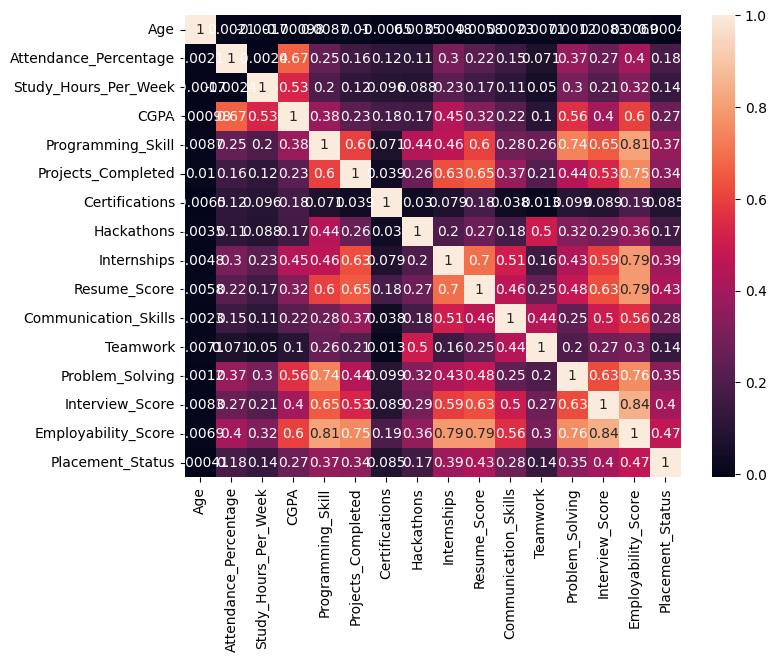

In [161]:
corr = df_copy[numarical_col + ['Placement_Status']].corr()
plt.figure(figsize = (8,6))
sns.heatmap(corr,annot = True)


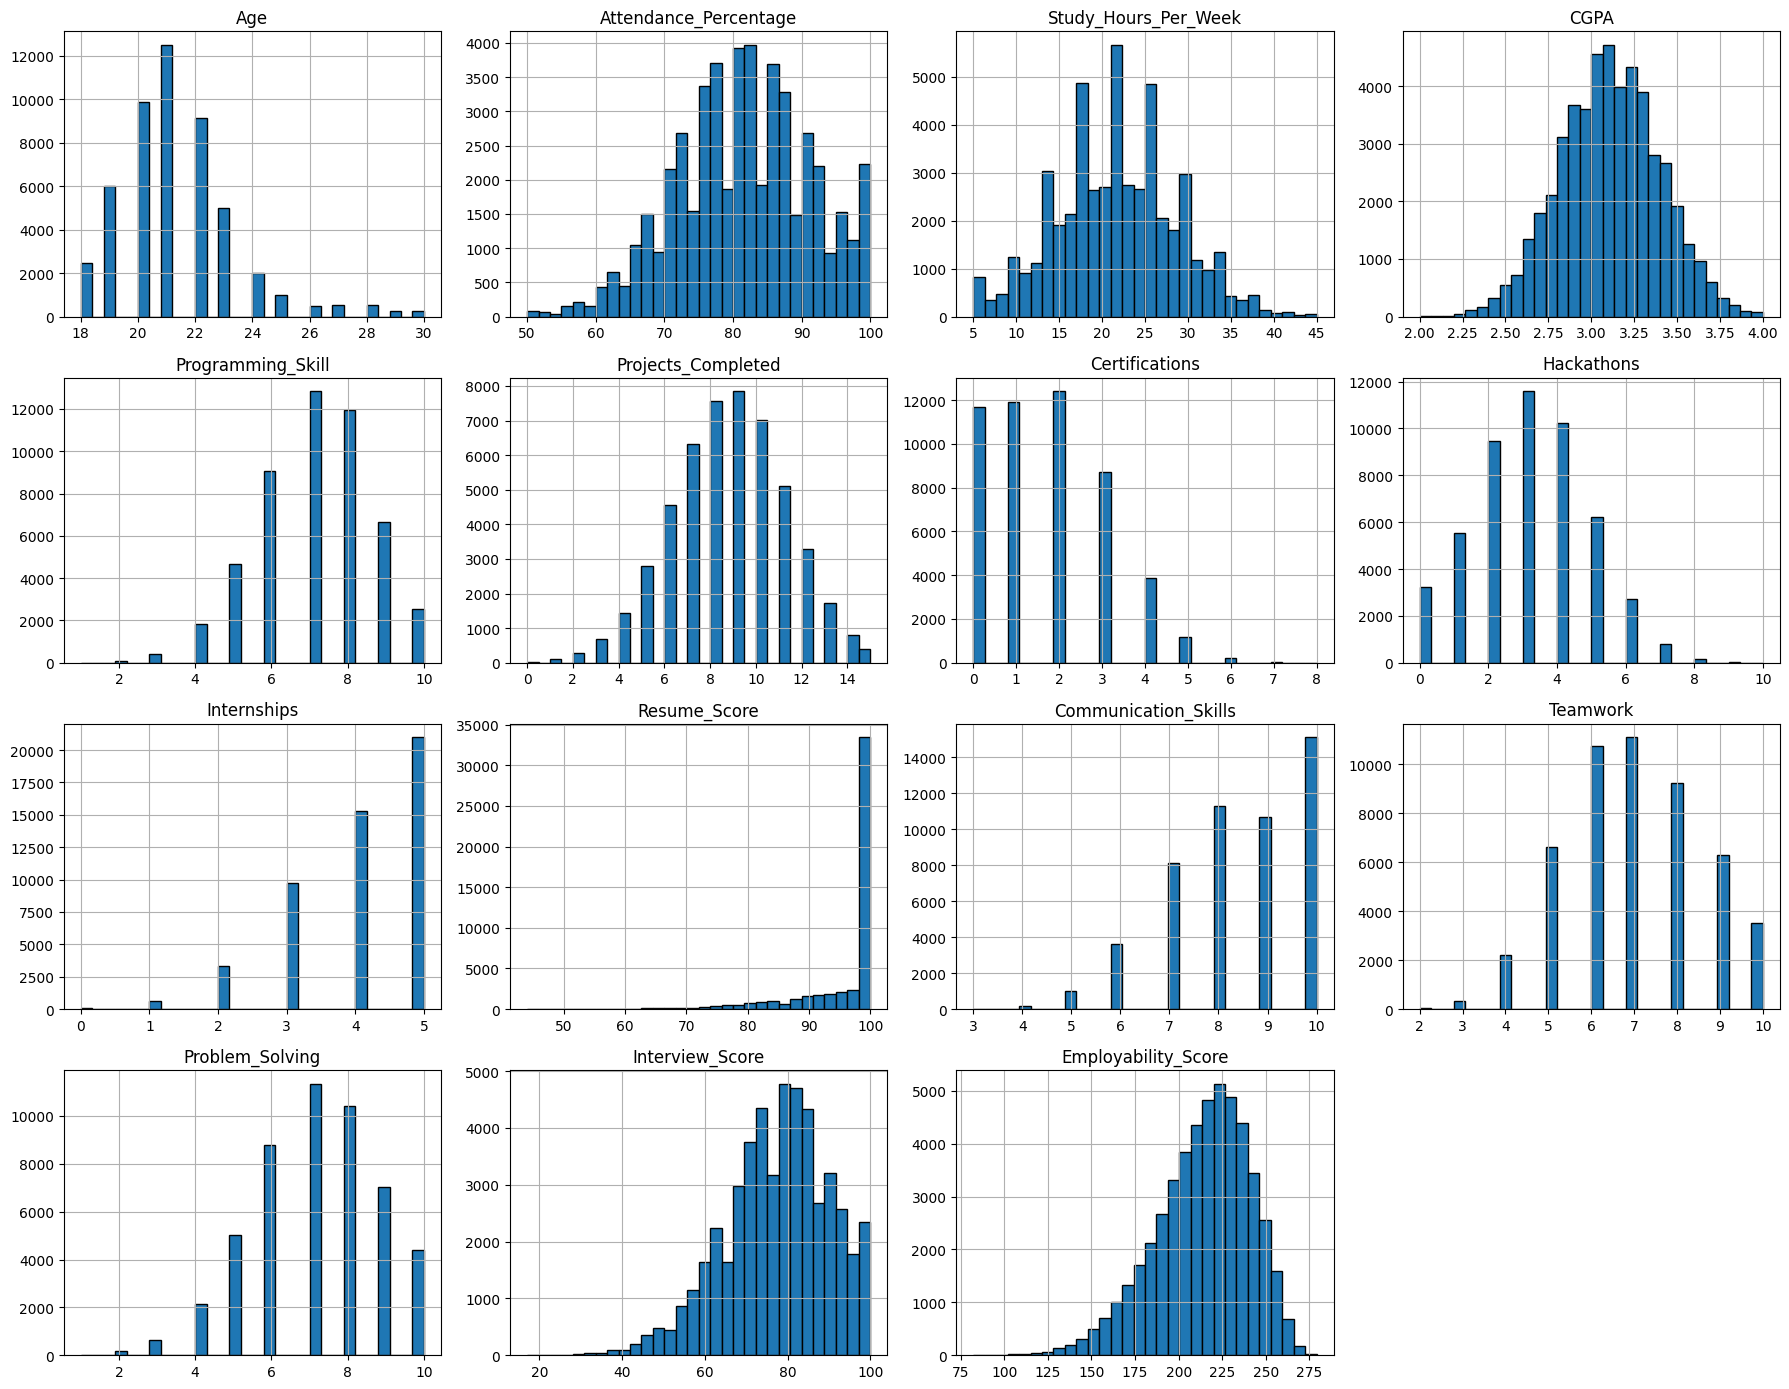

In [162]:
df_copy[numarical_col].hist(figsize =(18,14),bins = 30,edgecolor = 'black')
plt.title('distribution of numarical_feature')
plt.tight_layout()

plt.show()

In [163]:
skewness = df_copy[numarical_col].skew().sort_values(ascending = False)
skewness

,0
Age,1.267309
Certifications,0.509751
Hackathons,0.135590
Study_Hours_Per_Week,0.060355
Teamwork,0.019136
CGPA,-0.029040
Projects_Completed,-0.079915
Attendance_Percentage,-0.158629
Problem_Solving,-0.270839
Programming_Skill,-0.280085


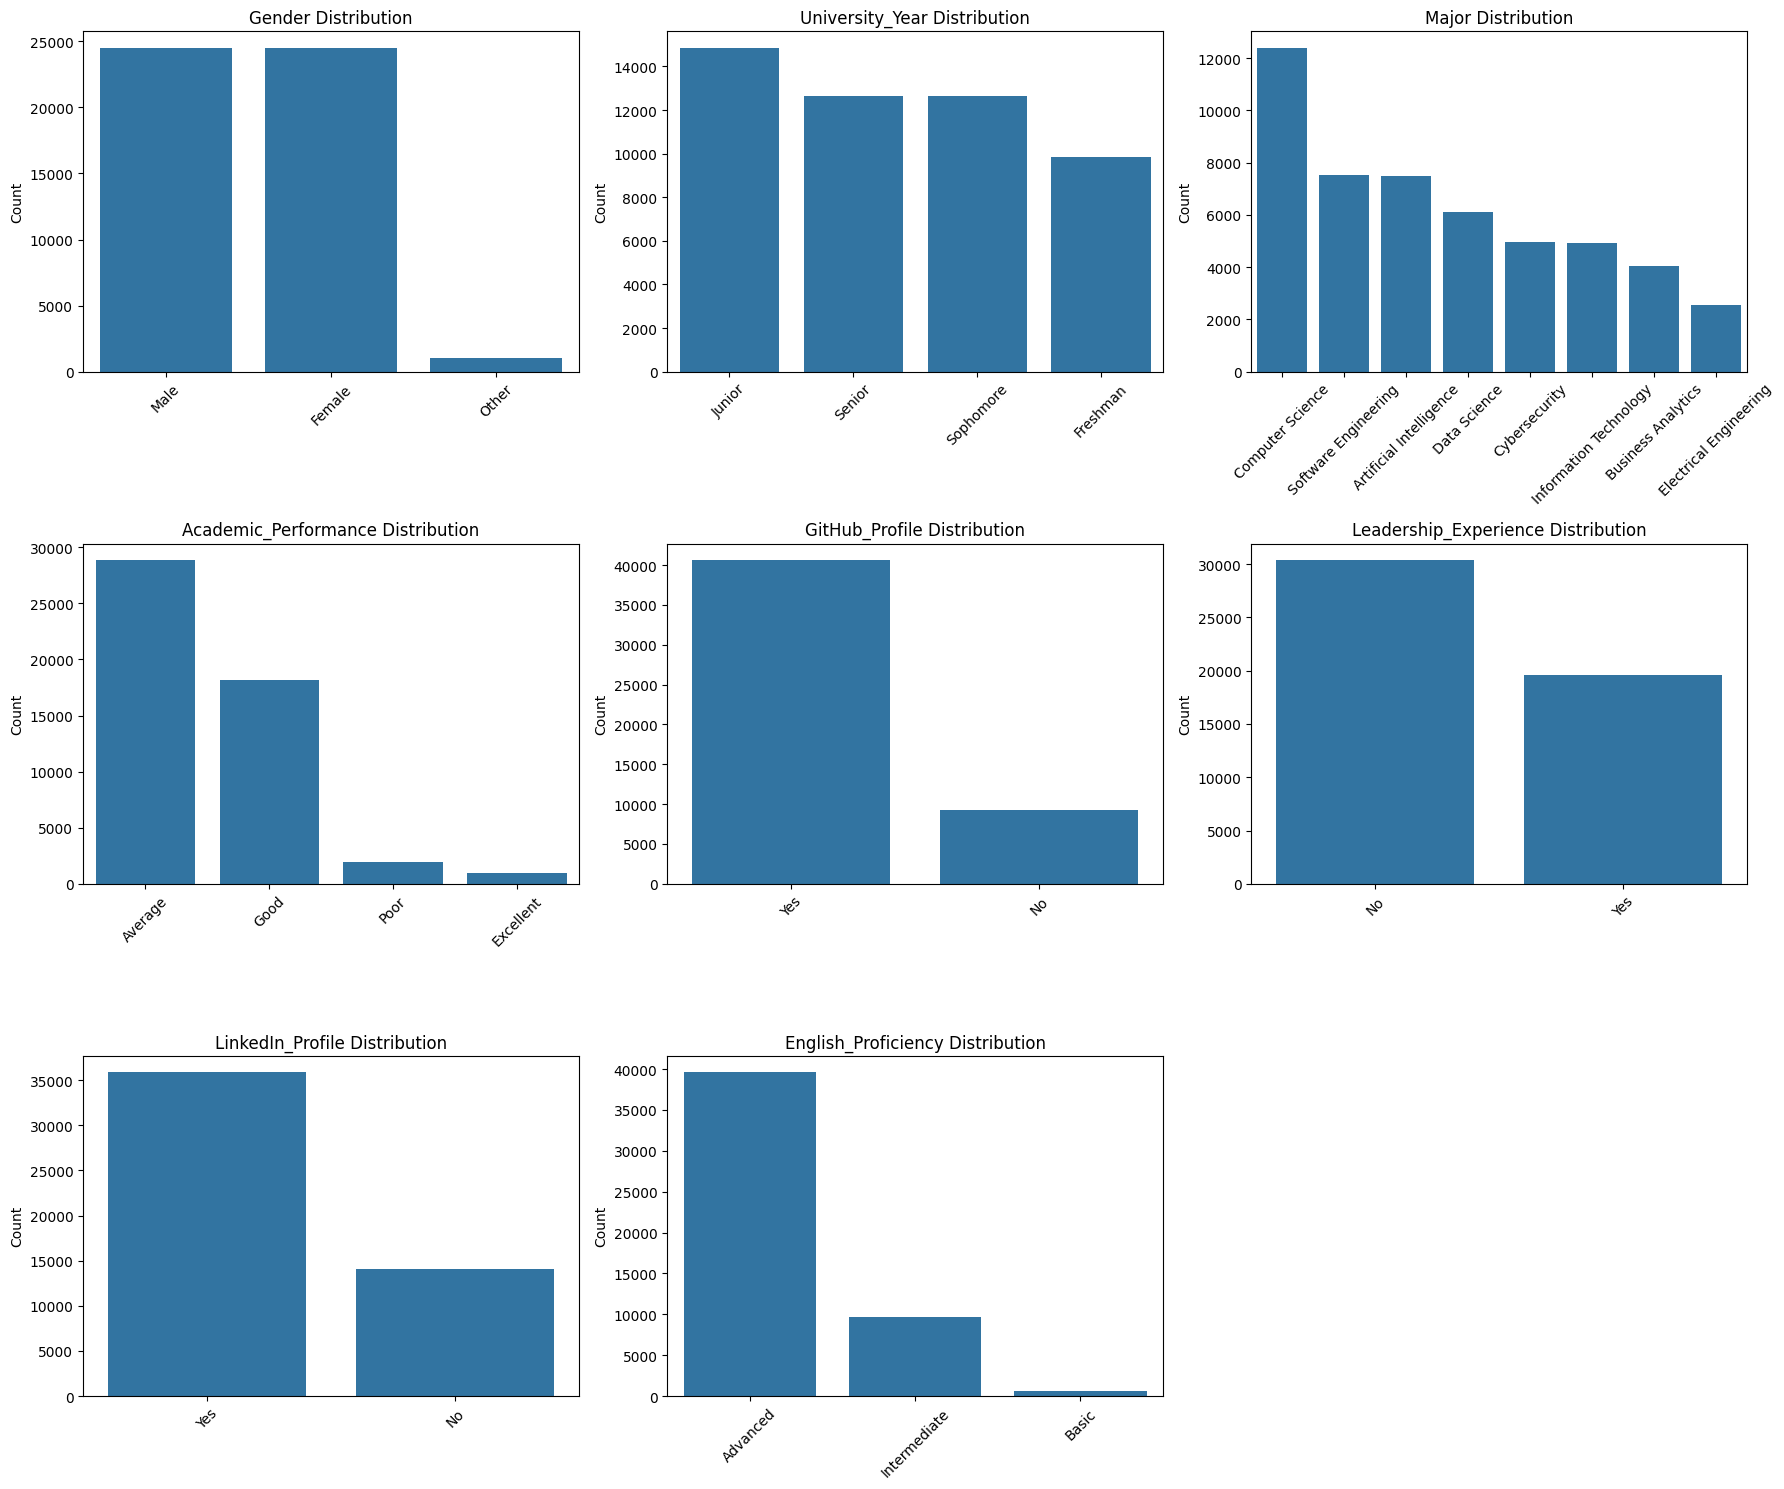

In [164]:
# Dynamically calculate grid dimensions based on the actual number of categorical columns
import math

n_cols = 3
n_rows = math.ceil(len(catagorical_col) / n_cols)

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(18, 5 * n_rows)
)

axes = axes.flatten()
for i, col in enumerate(catagorical_col):
    order = df_copy[col].value_counts().index

    sns.countplot(
        data=df_copy,
        x=col,
        order=order,
        ax=axes[i]
    )

    axes[i].set_title(f"{col} Distribution")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis="x", rotation=45)

# Safely delete any unused subplots
for j in range(len(catagorical_col), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

<Axes: xlabel='Gender', ylabel='count'>

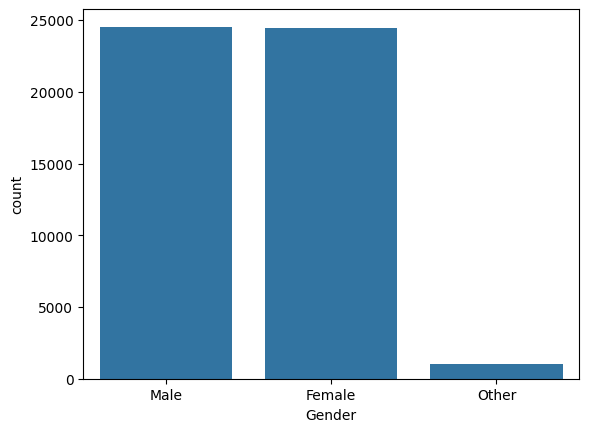

In [165]:
sns.countplot(x ='Gender' ,data = df_copy)

# finding outliers

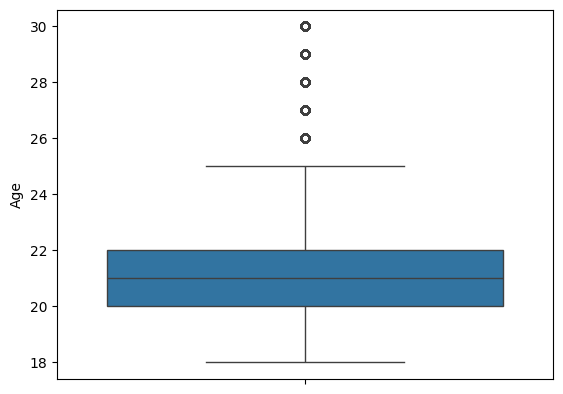

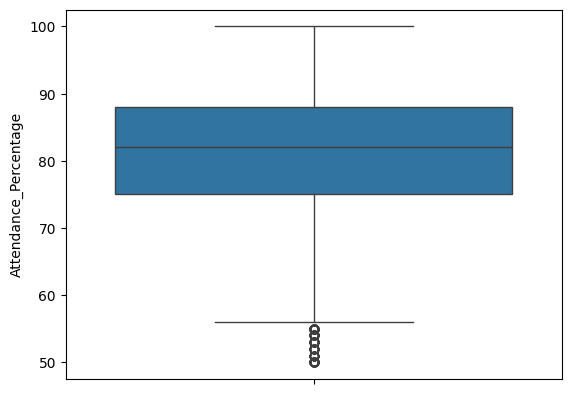

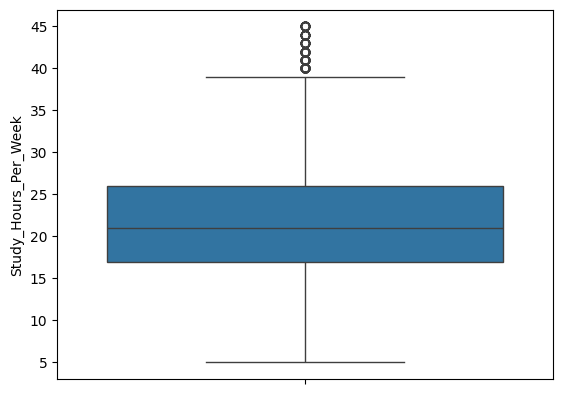

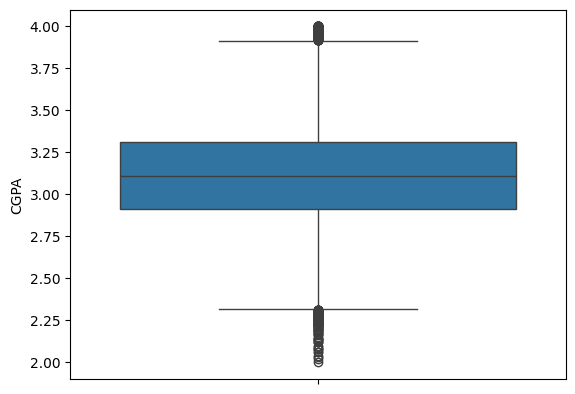

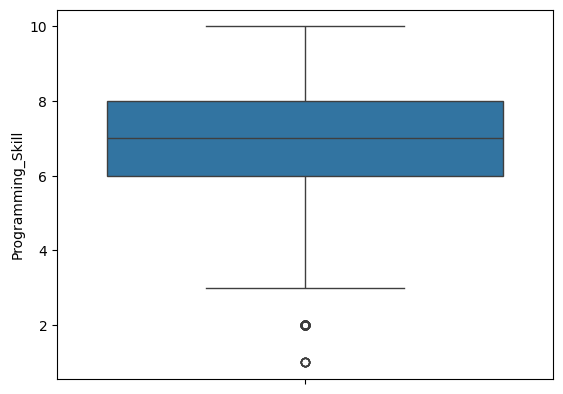

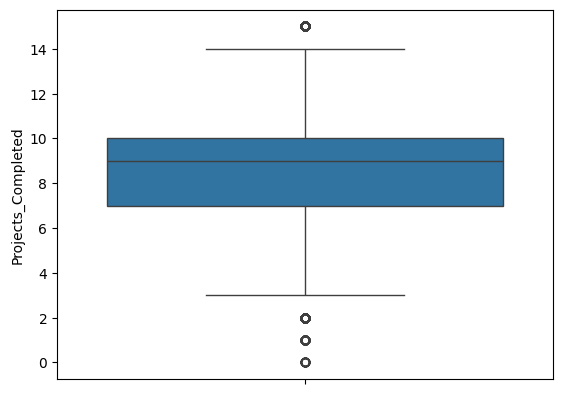

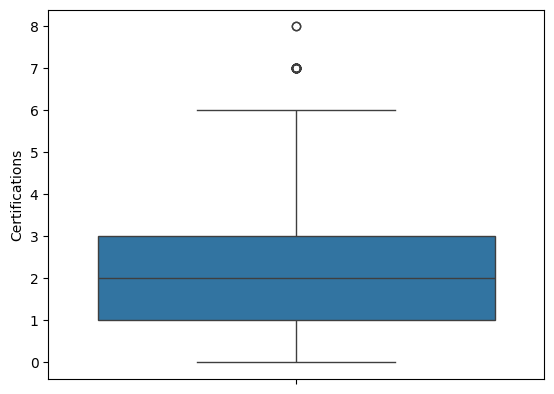

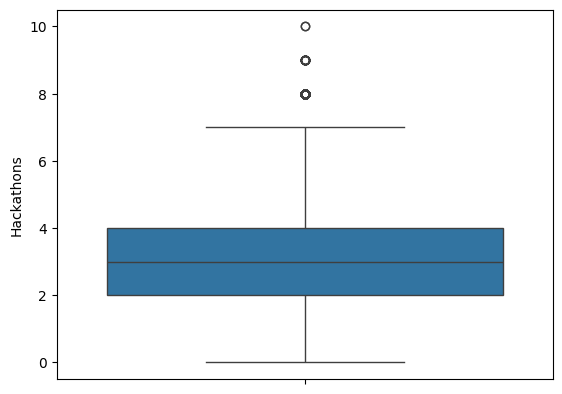

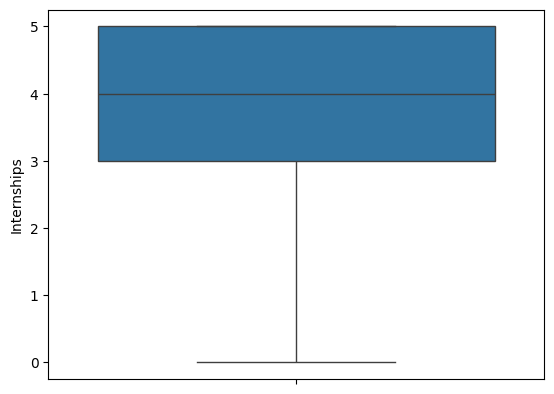

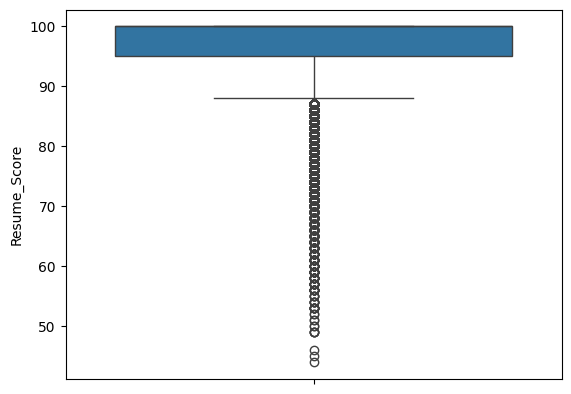

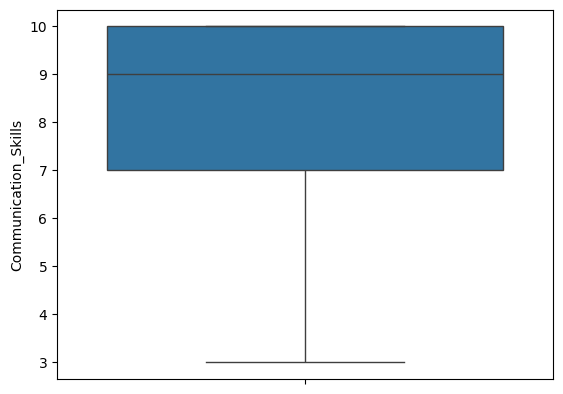

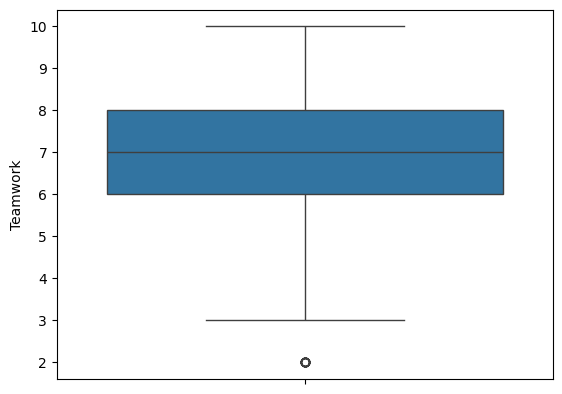

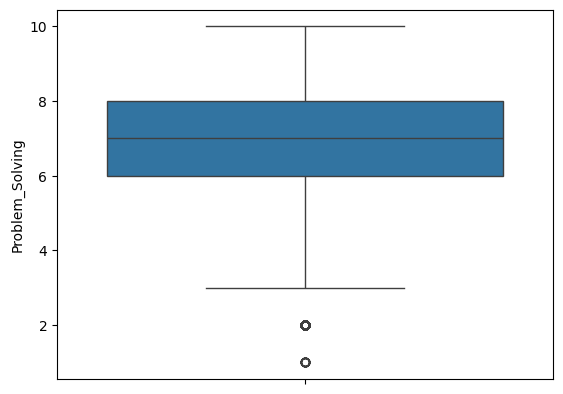

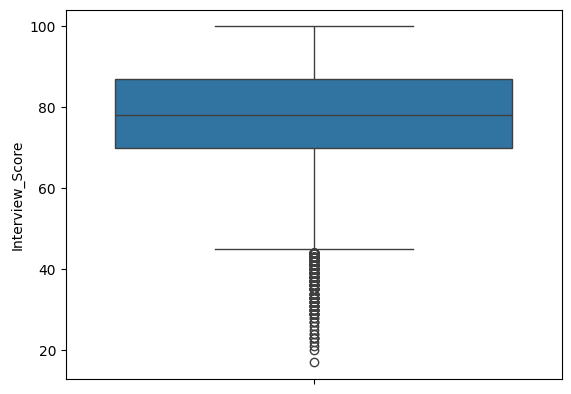

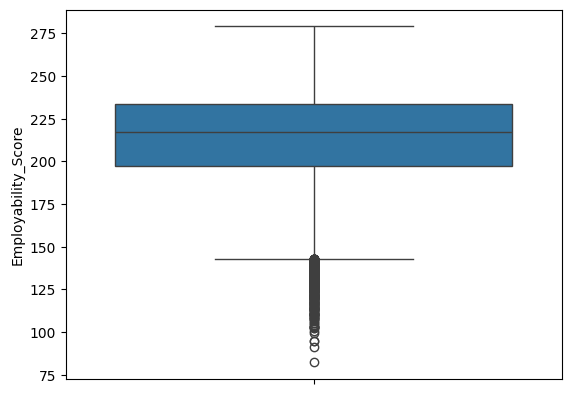

In [166]:
for i in numarical_col:
  sns.boxplot(df[i])
  plt.show()

In [167]:
numarical_col

['Age',
 'Attendance_Percentage',
 'Study_Hours_Per_Week',
 'CGPA',
 'Programming_Skill',
 'Projects_Completed',
 'Certifications',
 'Hackathons',
 'Internships',
 'Resume_Score',
 'Communication_Skills',
 'Teamwork',
 'Problem_Solving',
 'Interview_Score',
 'Employability_Score']

# what happen if removes the ouliers

In [168]:
print(f"Original dataset shape: {df.shape}")
print(f"Current shape after Age outlier removal: {df_copy.shape}")

# what if i remove the outliers
temp_df = df_copy.copy()
for col in numarical_col:
    Q1 = temp_df[col].quantile(0.25)
    Q3 = temp_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    temp_df = temp_df[(temp_df[col] >= lower) & (temp_df[col] <= upper)]

print(f"Shape if we remove outliers from ALL numerical columns: {temp_df.shape}")
print(f"Data lost: {((df_copy.shape[0] - temp_df.shape[0]) / df_copy.shape[0]) * 100:.2f}%")

Original dataset shape: (50000, 29)
Current shape after Age outlier removal: (50000, 24)
Shape if we remove outliers from ALL numerical columns: (40462, 24)
Data lost: 19.08%


In [169]:
df_copy.shape

(50000, 24)

In [170]:
df_copy.columns

Index(['Age', 'Gender', 'University_Year', 'Major', 'Attendance_Percentage',
       'Study_Hours_Per_Week', 'CGPA', 'Academic_Performance',
       'Programming_Skill', 'Projects_Completed', 'Certifications',
       'Hackathons', 'GitHub_Profile', 'Internships', 'Leadership_Experience',
       'LinkedIn_Profile', 'Resume_Score', 'Communication_Skills', 'Teamwork',
       'Problem_Solving', 'English_Proficiency', 'Interview_Score',
       'Employability_Score', 'Placement_Status'],
      dtype='object')

# train test split

In [171]:
from sklearn.model_selection import train_test_split

In [172]:
x = df_copy.drop(target_col, axis=1)
y = df_copy[target_col]

# Correct unpacking order
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("Training features shape:", x_train.shape)
print("Testing features shape:", x_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (40000, 23)
Testing features shape: (10000, 23)
Training target shape: (40000, 1)
Testing target shape: (10000, 1)


# feature engineering

In [173]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer


In [174]:
df_copy.head(
    1
)

,Age,Gender,University_Year,Major,Attendance_Percentage,Study_Hours_Per_Week,CGPA,Academic_Performance,Programming_Skill,Projects_Completed,...,Leadership_Experience,LinkedIn_Profile,Resume_Score,Communication_Skills,Teamwork,Problem_Solving,English_Proficiency,Interview_Score,Employability_Score,Placement_Status
0,22,Male,Sophomore,Computer Science,86,21,3.28,Good,9,10,...,No,No,100,9,7,8,Advanced,72,231.7,1


In [175]:
print(df_copy['GitHub_Profile'].unique())
print(df_copy['LinkedIn_Profile'].unique())
print(df_copy['Leadership_Experience'].unique())

['Yes' 'No']
['No' 'Yes']
['No' 'Yes']


In [176]:
from sklearn.preprocessing import OrdinalEncoder

# Correctly defining the preprocessor using standard lists and compatible encoders
preprocessor = ColumnTransformer(
    transformers=[
        ('numerical', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numarical_col),
        ('binary_cat', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ordinal', OrdinalEncoder())
        ]), ['GitHub_Profile', 'Leadership_Experience', 'LinkedIn_Profile']),
        ('multiclass_cat', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), ['Gender', 'University_Year', 'Major', 'Academic_Performance', 'English_Proficiency'])
    ]
)

print("Preprocessor built successfully!")

Preprocessor built successfully!


In [178]:

for col in ['Academic_Performance', 'English_Proficiency']:
    print(f"=== Distribution for {col} ===")
    print(df_copy[col].value_counts())
    print()

=== Distribution for Academic_Performance ===
Academic_Performance
Average      28890
Good         18168
Poor          1956
Excellent      986
Name: count, dtype: int64

=== Distribution for English_Proficiency ===
English_Proficiency
Advanced        39640
Intermediate     9720
Basic             640
Name: count, dtype: int64



In [179]:
from sklearn.model_selection import cross_validate,StratifiedKFold
cv = StratifiedKFold(n_splits = 5, shuffle =True,random_state = 42)
scoring = {'accuracy':'accuracy','precision':'precision','f1':'f1','recall':'recall','roc_auc':'roc_auc'}

# #model traininng

In [180]:
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier


In [188]:

models_dict = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1),
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'KNN': KNeighborsClassifier()
}

results_summary = []


for model_name, model_obj in models_dict.items():
    print(f'Evaluating {model_name}...')

    model_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model_obj)
    ])

    cv_result = cross_validate(
        estimator=model_pipeline,
        X=x_train,
        y=y_train.values.ravel(),
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results_summary.append({
        'Model': model_name,
        'Accuracy': cv_result['test_accuracy'].mean(),
        'Precision': cv_result['test_precision'].mean(),
        'Recall': cv_result['test_recall'].mean(),
        'F1-Score': cv_result['test_f1'].mean(),
        'ROC-AUC': cv_result['test_roc_auc'].mean()
    })

results_df = pd.DataFrame(results_summary)
display(results_df)

Evaluating Decision Tree...
Evaluating XGBoost...
Evaluating Random Forest...
Evaluating Logistic Regression...
Evaluating KNN...


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree,0.735625,0.837839,0.820774,0.829215,0.625501
1,XGBoost,0.810150,0.839477,0.936251,0.885225,0.801772
2,Random Forest,0.816525,0.842125,0.941974,0.889251,0.807128
3,Logistic Regression,0.821100,0.841119,0.950830,0.892614,0.811114
4,KNN,0.794200,0.835898,0.916813,0.874483,0.730461


# best fit model accuracy

=== Logistic Regression Test Metrics ===
              precision    recall  f1-score   support

           0       0.67      0.34      0.45      2239
           1       0.83      0.95      0.89      7761

    accuracy                           0.81     10000
   macro avg       0.75      0.65      0.67     10000
weighted avg       0.80      0.81      0.79     10000



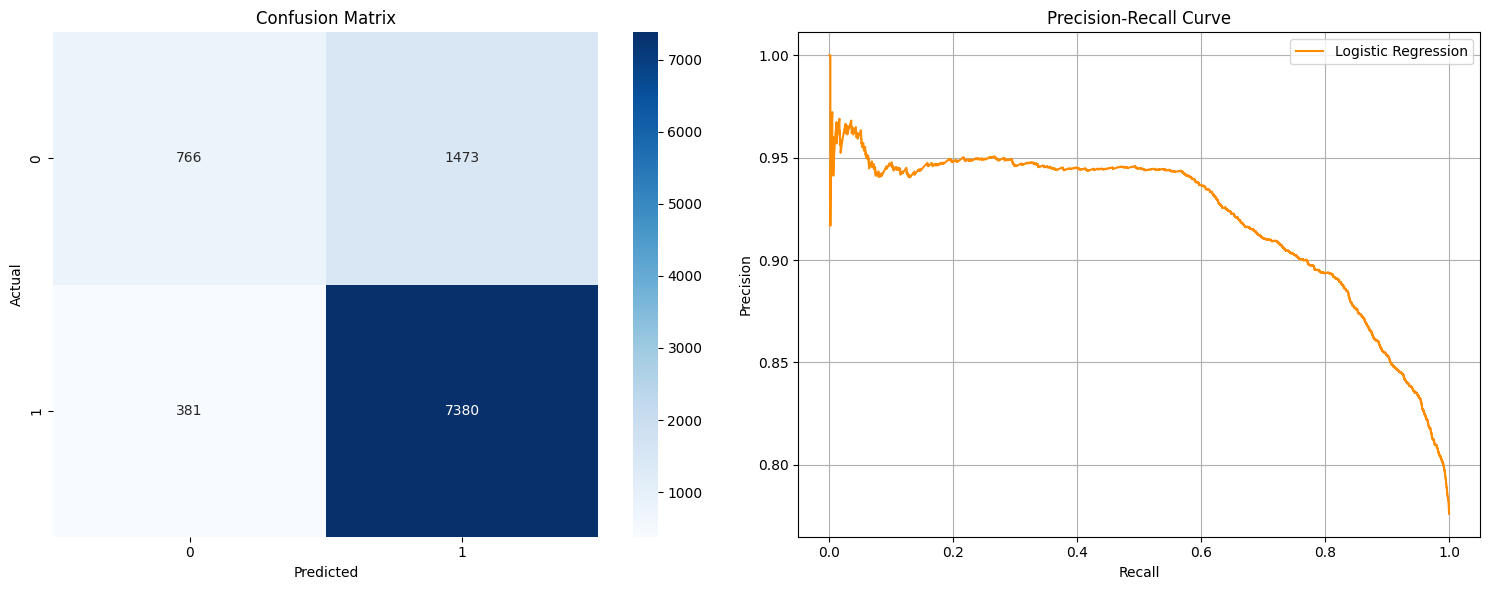

In [191]:
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve
import matplotlib.pyplot as plt
import seaborn as sns


best_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])


best_pipeline.fit(x_train, y_train.values.ravel())


y_pred = best_pipeline.predict(x_test)
y_pred_proba = best_pipeline.predict_proba(x_test)[:, 1]

# Print metrics and classification report
print("=== Logistic Regression Test Metrics ===")
print(classification_report(y_test, y_pred))

#  Plot Confusion Matrix and Precision-Recall Curve side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix")
axes[0].set_ylabel("Actual")
axes[0].set_xlabel("Predicted")

# Precision-Recall Curve
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba)
axes[1].plot(recalls, precisions, label="Logistic Regression", color="darkorange")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend(loc="best")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [192]:
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

search_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000, random_state=42, solver='saga'))
])

param_distributions = {
    'classifier__C': np.logspace(-4, 4, 20),
    'classifier__penalty': ['l1', 'l2']
}
random_search = RandomizedSearchCV(
    estimator=search_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42,
    verbose=1
)


print("Starting RandomizedSearchCV...")
random_search.fit(x_train, y_train.values.ravel())

print("Best parameters :", random_search.best_params_)
print(f"Best Cross-Validation Accuracy: {random_search.best_score_:.4f}")

Starting RandomizedSearchCV...
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best parameters : {'classifier__penalty': 'l1', 'classifier__C': np.float64(0.03359818286283781)}
Best Cross-Validation Accuracy: 0.8222


=== Optimized Logistic Regression Test Metrics ===
              precision    recall  f1-score   support

           0       0.67      0.34      0.45      2239
           1       0.83      0.95      0.89      7761

    accuracy                           0.82     10000
   macro avg       0.75      0.65      0.67     10000
weighted avg       0.80      0.82      0.79     10000



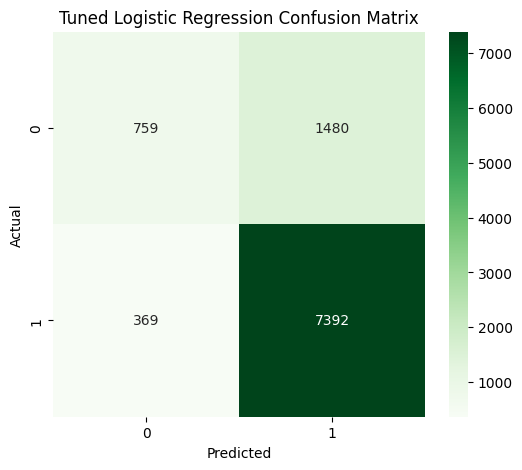

In [193]:

best_tuned_model = random_search.best_estimator_
y_tuned_pred = best_tuned_model.predict(x_test)
y_tuned_proba = best_tuned_model.predict_proba(x_test)[:, 1]

print("=== Optimized Logistic Regression Test Metrics ===")
print(classification_report(y_test, y_tuned_pred))


fig, ax = plt.subplots(figsize=(6, 5))
cm_tuned = confusion_matrix(y_test, y_tuned_pred)
sns.heatmap(cm_tuned, annot=True, fmt="d", cmap="Greens", ax=ax)
ax.set_title("Tuned Logistic Regression Confusion Matrix")
ax.set_ylabel("Actual")
ax.set_xlabel("Predicted")
plt.show()

# to domload best model

In [ ]:
import joblib
# joblib.dump(best_tuned_model,'prediction_model.pkl')